## Figure 4 — Pressure drop

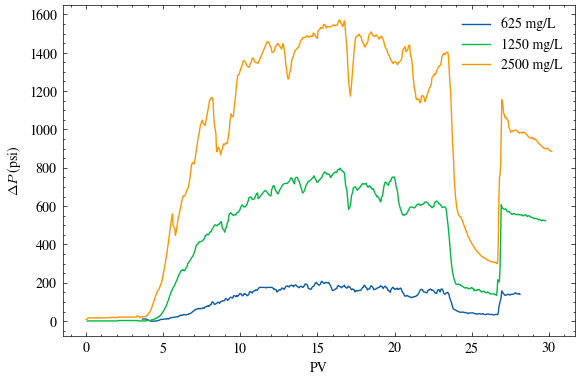

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import scienceplots

plt.style.use(["science", "no-latex"])
df4 = pd.read_csv("inputs/Vieira_Figure4_DeltaP_vs_PV_digitized.csv")
fig, ax = plt.subplots(figsize=(6, 4))
for concentration in (625, 1250, 2500):
    x, y = f"PV_{concentration}mgL", f"DeltaP_{concentration}mgL_psi"
    data = df4[[x, y]].dropna().sort_values(x)
    ax.plot(data[x], data[y], label=f"{concentration} mg/L")
ax.set_xlabel("PV")
ax.set_ylabel(r"$\Delta P$ (psi)")
ax.legend()
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/figure4.png", dpi=300, bbox_inches="tight")
plt.show()

## Figure 5 — Apparent viscosity versus FG

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import scienceplots

plt.style.use(["science", "no-latex"])
df5 = pd.read_csv("inputs/Vieira_Figure5_muApp_vs_FG_digitized.csv")
df5.head()

,FG,muApp_625mgL_cp,muApp_1250mgL_cp,muApp_2500mgL_cp
0,0.00,0.00,0.00,0.00
1,0.25,50.42,414.36,940.91
2,0.50,164.64,789.92,1757.84
3,0.70,253.69,1012.54,1835.27
4,0.75,267.24,1055.13,2079.19


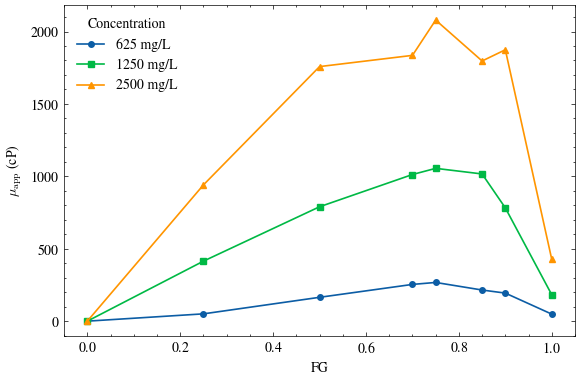

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
for concentration, marker in zip((625, 1250, 2500), ("o", "s", "^")):
    column = f"muApp_{concentration}mgL_cp"
    data = df5[["FG", column]].dropna().sort_values("FG")
    ax.plot(data["FG"], data[column], marker=marker, markersize=4,
            linewidth=1.2, label=f"{concentration} mg/L")
ax.set_xlabel("FG")
ax.set_ylabel(r"$\mu_{\mathrm{app}}$ (cP)")
ax.legend(title="Concentration")
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/figure5.png", dpi=300, bbox_inches="tight")
fig.savefig("figures/figure5.pdf", bbox_inches="tight")
plt.show()

## Attempt to reproduce Table 7 FMMOB (Sample 3)

Source: *Experimental Characterization to Support a FAWAG Project in an Offshore Pre-Salt Field*, SPE-218195-MS, Table 7 and Figures 4–5 (p. 10), Appendix A (p. 24). Sample 3 is the sample used in the digitized figures; its published FMMOB values are 219.6, 993.6, and 2005.5 for 625, 1250, and 2500 mg/L.

Equation A1-3 gives
$$\mathrm{MRF}=\frac{\Delta P_f}{\Delta P_0}=\frac{1}{FM_{\mathrm{ref}}}.$$
Equation A1-4 therefore gives
$$\mathrm{FMMOB}=\frac{1-FM_{\mathrm{ref}}}{FM_{\mathrm{ref}}}=\frac{\Delta P_f}{\Delta P_0}-1.$$
Both pressures must be measured at $FG^*$, with and without surfactant, respectively. The baseline is **water–gas co-injection without surfactant**, not pure water or pure gas.

For the same core and total volumetric flow rate, Darcy's apparent-viscosity definition $\mu_{app}=kA\Delta P/(LQ)$ allows the equivalent expression
$$\mathrm{FMMOB}=\frac{\mu_{app,f}(FG^*)}{\mu_{app,0}(FG^*)}-1.$$
This uses the apparent viscosity of the baseline two-phase flow, not the molecular viscosity of water or gas.

The digitized CSV contains only the three surfactant curves. The baseline is plotted very close to zero on the original figure's 0–2500 cP axis, so this figure does not support a reliable numerical extraction of a baseline near 1 cP. Independent reproduction is therefore underdetermined. First, infer the baseline that each published value would require:
$$\mu_{app,0}^{\mathrm{inferred}}=\frac{\mu_{app,f}(FG^*)}{1+\mathrm{FMMOB}_{\mathrm{Table\ 7}}}.$$
These inferred baselines use the target values and must not be interpreted as independent measurements.

In [4]:
import pandas as pd
from pathlib import Path

foam_scan = pd.read_csv("inputs/Vieira_Figure5_muApp_vs_FG_digitized.csv")
published_fmmob = {625: 219.6, 1250: 993.6, 2500: 2005.5}
rows = []
for concentration, target in published_fmmob.items():
    column = f"muApp_{concentration}mgL_cp"
    curve = foam_scan[["FG", column]].dropna()
    peak = curve.loc[curve[column].idxmax()]
    rows.append({
        "concentration_mg_L": concentration,
        "FG_star_digitized": peak["FG"],
        "peak_mu_app_cP": peak[column],
        "FMMOB_table7": target,
        "baseline_mu_app_inferred_cP": peak[column] / (1 + target),
    })
fmmob_comparison = pd.DataFrame(rows).set_index("concentration_mg_L")
fmmob_comparison.round(6)

,FG_star_digitized,peak_mu_app_cP,FMMOB_table7,baseline_mu_app_inferred_cP
concentration_mg_L,,,,
625,0.75,267.24,219.6,1.211423
1250,0.75,1055.13,993.6,1.060859
2500,0.75,2079.19,2005.5,1.036227


### Common-baseline consistency check

All three digitized peaks occur at FG = 0.75. If a single baseline applies to these runs at this FG, their inferred baseline viscosities should agree within experimental and digitization uncertainty. As a diagnostic, anchor the baseline to the 2500 mg/L published result and predict the other two results. The anchor row agrees by construction; this is a conditional reconstruction, not independent validation. No experimental uncertainty bounds are supplied by these CSVs.

In [5]:
anchor_baseline_cP = fmmob_comparison.loc[2500, "baseline_mu_app_inferred_cP"]
fmmob_comparison["FMMOB_common_baseline"] = (
    fmmob_comparison["peak_mu_app_cP"] / anchor_baseline_cP - 1
)
fmmob_comparison["relative_error_percent"] = 100 * (
    fmmob_comparison["FMMOB_common_baseline"] / fmmob_comparison["FMMOB_table7"] - 1
)
Path("results").mkdir(exist_ok=True)
fmmob_comparison.to_csv("results/table7_fmmob_reconstruction.csv")
print(f"Baseline inferred from the 2500 mg/L target: {anchor_baseline_cP:.6f} cP")
display(fmmob_comparison.round(4))

Baseline inferred from the 2500 mg/L target: 1.036227 cP


,FG_star_digitized,peak_mu_app_cP,FMMOB_table7,baseline_mu_app_inferred_cP,FMMOB_common_baseline,relative_error_percent
concentration_mg_L,,,,,,
625,0.75,267.24,219.6,1.2114,256.8971,16.9841
1250,0.75,1055.13,993.6,1.0609,1017.2419,2.3794
2500,0.75,2079.19,2005.5,1.0362,2005.5000,-0.0000


### Interpretation and missing measurement

The published values can be recovered algebraically with a separate inferred baseline for each run, but doing so is circular. A common baseline anchored to 2500 mg/L exposes differences in the other two concentrations. Possible contributors include digitization, selection of steady-state values, or run-specific baseline measurements; the available data do not establish the cause.

To reproduce Table 7 independently, obtain the measured baseline differential pressure (or apparent viscosity) at FG = 0.75 for Sample 3, together with confirmation of matching flow rates and run conditions. Figure 4's maximum instantaneous pressure is not necessarily the steady-state pressure at the selected FG and should not substitute for it. The FG = 0 entries in the Figure 5 CSV are also not the required baseline.